In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# P3 Q2: Describe the Gaussian generator and observed correlation.
def generate_data(n_samples=500, seed=0, mean=None, covariance=None):
    """Return reproducible Gaussian samples (n_samples,2) using NumPy and seed.

    Defaults: mean=[2,-1], covariance=[[3,1.2],[1.2,1]]. Custom mean has shape
    (2,), covariance (2,2) is positive definite. Do not mutate input arrays.
    """
    x = np.random.multivariate_normal(mean, covariance, n_samples)

    return x


In [3]:
# P3 Q3: Link centering/covariance/eigendecomposition to the derivation and explain the plot.
def pca(x):
    """Fit NumPy PCA without mutating finite X of shape (n,2), n>=2.

    Return dict: mean (2,), centered (n,2), covariance (2,2), eigenvalues (2,),
    components (2,2), scores (n,2). Use covariance divisor n-1, descending
    eigenvalues, orthonormal eigenvectors as columns, scores=centered@components.
    Signs/tied-eigenspace bases are free. Include rank-deficient and tied cases.
    NumPy eigh/SVD are allowed; fitted library PCA is not.
    """

    mean = np.mean(x, axis=0)
    centered = x - mean
    covariance = np.cov(centered.T) # default divisor is (n-1)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)

    # sort eigenvalues
    idx = eigenvalues.argsort()[::-1]
    eigenvalues = np.maximum(eigenvalues[idx], 0.0)
    eigenvectors = eigenvectors[:, idx]

    scores = centered @ eigenvectors
    return {'mean': mean,
            'centered': centered,
            'covariance': covariance,
            'eigenvalues': eigenvalues,
            'eigenvectors': eigenvectors,
            'scores': scores}

In [4]:
# P3 Q4: Interpret the variance fractions and dimensionality reduction tradeoff.
def explained_variance(eigenvalues):
    """Return same-shape fractions for nonnegative eigenvalues with positive sum."""
    prop_variance = eigenvalues / np.sum(eigenvalues)
    return prop_variance


In [10]:
# YOUR ANSWER HERE
def make_plots(X, result):
    mean = result['mean']
    eigenvalues = result["eigenvalues"]
    eigenvectors = result["eigenvectors"]

    # Plot Q2
    fig1, ax1 = plt.subplots(figsize=(6, 5), dpi=100)
    ax1.scatter(X[:, 0], X[:, 1], s=10, alpha=0.6)

    ax1.set_title("Q2: 2-Dimension Dataset")
    ax1.set_xlabel("Dimension 1")
    ax1.set_ylabel("Dimension 2")
    ax1.axis("equal")


    # Plot Q3
    fig2, ax2 = plt.subplots(figsize=(6, 5), dpi=100)
    ax2.scatter(X[:, 0], X[:, 1], s=10, alpha=0.6)
    ax2.plot(mean[0], mean[1], "ro", markersize=3, label=f"Mean ({mean[0]:.2f}, {mean[1]:.2f})")

    for i in range(len(eigenvalues)):
        # Two standard deviations along each principal direction (using column eigenvectors)
        delta = np.sqrt(eigenvalues[i]) * eigenvectors[:, i] * 2
        endpoint = mean + delta

        ax2.annotate(
            "", xy=endpoint, xytext=mean,
            arrowprops=dict(arrowstyle="->", color=f"C{i+1}", lw=2),
        )
        ax2.text(
            mean[0] + delta[0] * 1.15,
            mean[1] + delta[1] * 1.15,
            f"PC{i+1}\n(={eigenvalues[i]:.2f})",
            color=f"C{i+1}",
            fontsize=10,
            weight="bold",
            ha="center",
            va="center",
        )

    ax2.set_title("Q3: Principal Components Directions")
    ax2.set_xlabel("Dimension 1")
    ax2.set_ylabel("Dimension 2")
    ax2.legend()
    ax2.axis("equal")

    return (fig1, fig2)

The shape of data is (500, 2)
Mean: [ 1.9607341  -1.00638745]
Eigenvalues: [3.71950605 0.41402727]
Proportion of Variance Explained: [0.89983696 0.10016304]


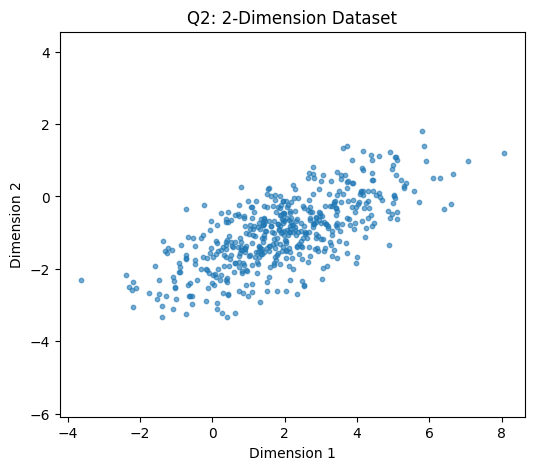

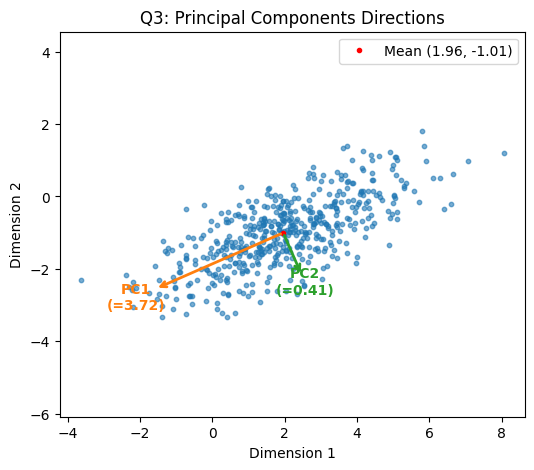

In [11]:
if __name__ == '__main__':
    mean=[2,-1]
    covariance=[[3,1.2],[1.2,1]]

    X = generate_data(mean=mean, covariance=covariance)
    result = pca(X)
    prop_variance = explained_variance(result['eigenvalues'])

    print(f'The shape of data is {X.shape}')
    print(f'Mean: {result["mean"]}')
    print(f'Eigenvalues: {result["eigenvalues"]}')
    print(f'Proportion of Variance Explained: {prop_variance}')

    make_plots(X, result)

## Q2
The scatter plot shows a strong positive linear correlation between the two dimensions, which means dimension 1 implies much information about dimension 2.

## Q3
Centering the dataset by mean substraction corresponds the centered data $X-E(X)$. Then the covariance matrix can be obtained by the sample covariance (divisor is $n-1$). To maximizing the projection variance, when setting the partial derivatives on $u$ as $0$, the components are actually the eigenvector of the covariance matrix.

## Q4
PC1 and PC2 corresponds to the eigenvalue 3.53 and 0.41 respectively. PC1 explains 89.5% of the variance and PC2 explains only 10.5%. That means if we reduce the 2 dimention data to 1 dimension data by projecting onto PC1, we only lose ~10% variance.